xc=0.0
  k=0: X1=[0.580000, 0.660000] (w=0.080000)  X2=[0.750000, 0.820000] (w=0.070000)
  k=1: X1=[0.614420, 0.621652] (w=0.007232)  X2=[0.783683, 0.788624] (w=0.004941)
  k=2: X1=[0.618011, 0.618057] (w=0.000045)  X2=[0.786136, 0.786167] (w=0.000030)
  k=3: X1=[0.618034, 0.618034] (w=0.000000)  X2=[0.786151, 0.786151] (w=0.000000)
  Итог: X1=[0.618034, 0.618034]  X2=[0.786151, 0.786151]
xc=0.5
  k=0: X1=[0.840000, 0.890000] (w=0.050000)  X2=[0.910000, 0.950000] (w=0.040000)
  k=1: X1=[0.864379, 0.867673] (w=0.003295)  X2=[0.929787, 0.931424] (w=0.001637)
  k=2: X1=[0.866021, 0.866030] (w=0.000009)  X2=[0.930602, 0.930607] (w=0.000005)
  k=3: X1=[0.866025, 0.866025] (w=0.000000)  X2=[0.930605, 0.930605] (w=0.000000)
  Итог: X1=[0.866025, 0.866025]  X2=[0.930605, 0.930605]
xc=1.0
  k=0: X1=[0.960000, 1.040000] (w=0.080000)  X2=[0.960000, 1.040000] (w=0.080000)
  k=1: X1=[0.990400, 1.009600] (w=0.019200)  X2=[0.996800, 1.003200] (w=0.006400)
  k=2: X1=[0.999775, 1.000225] (w=0.000451)  

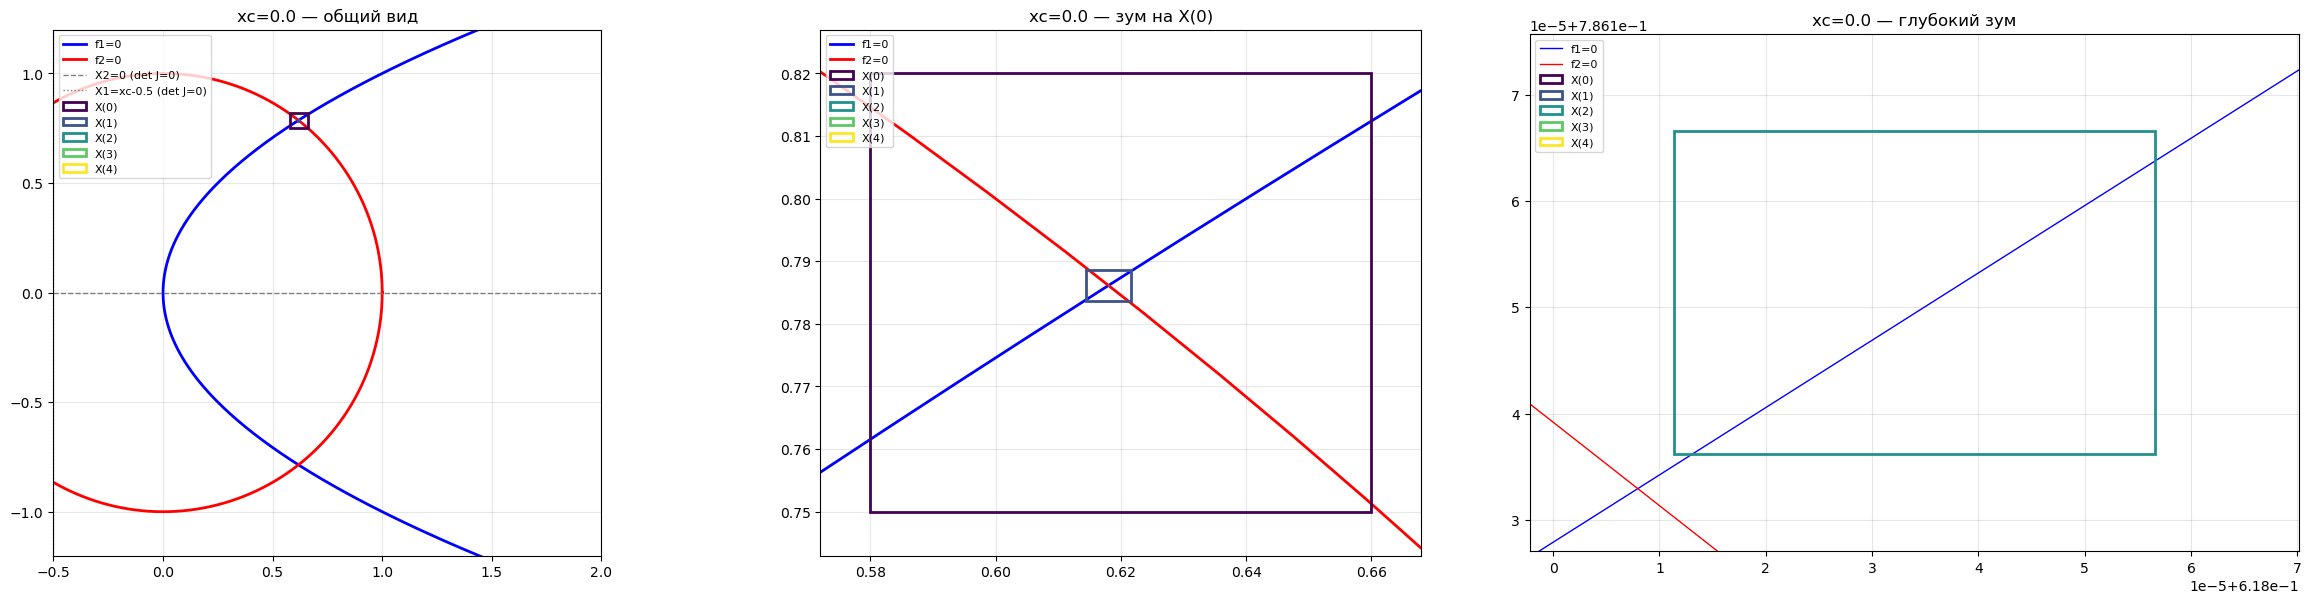

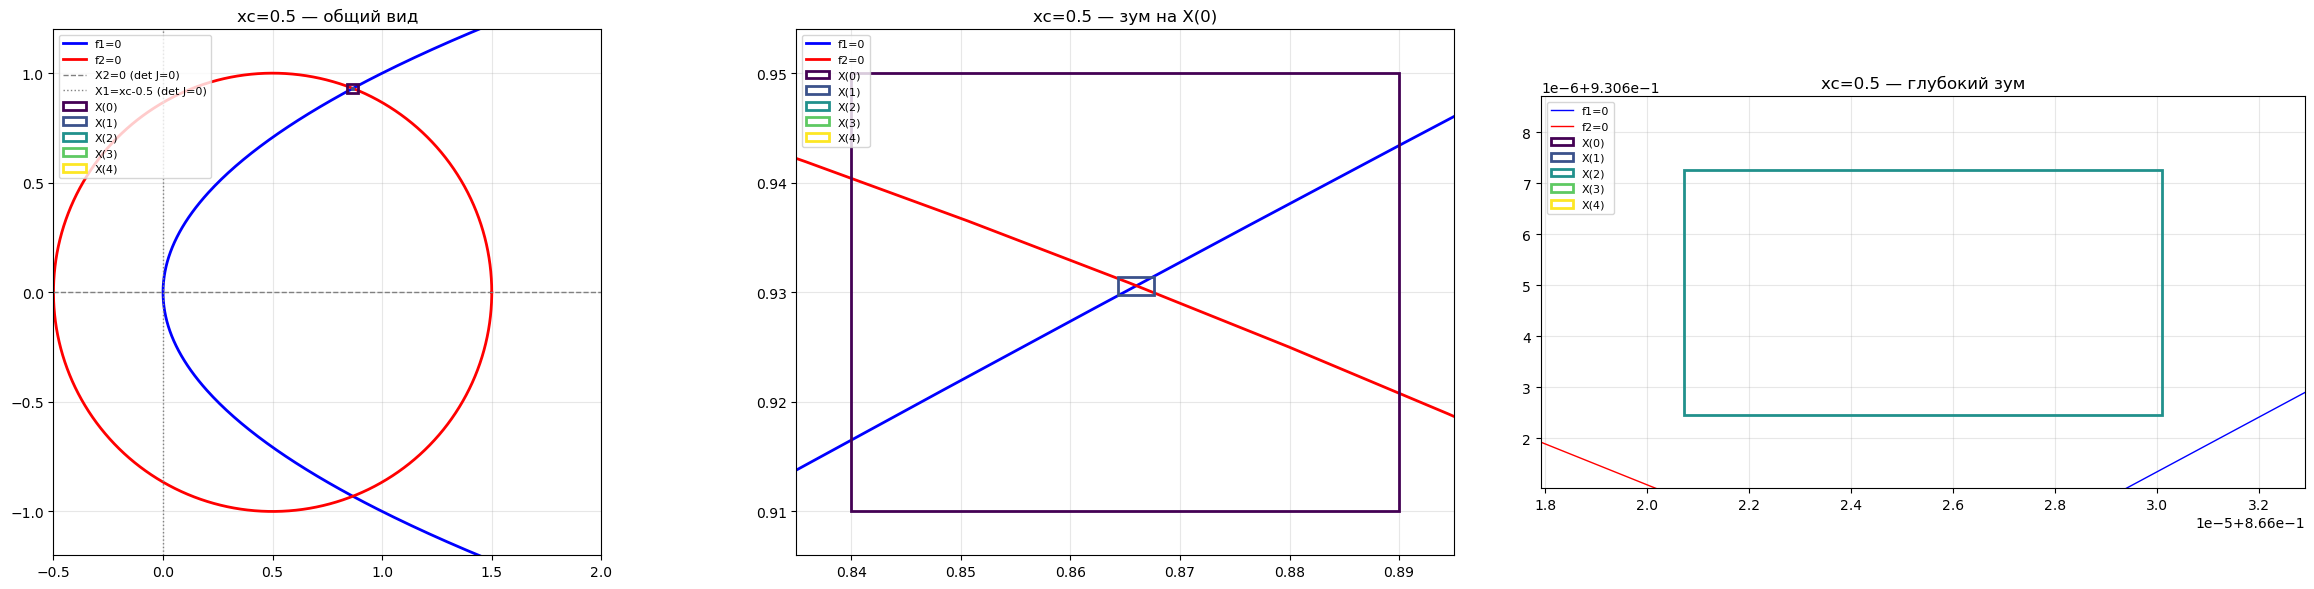

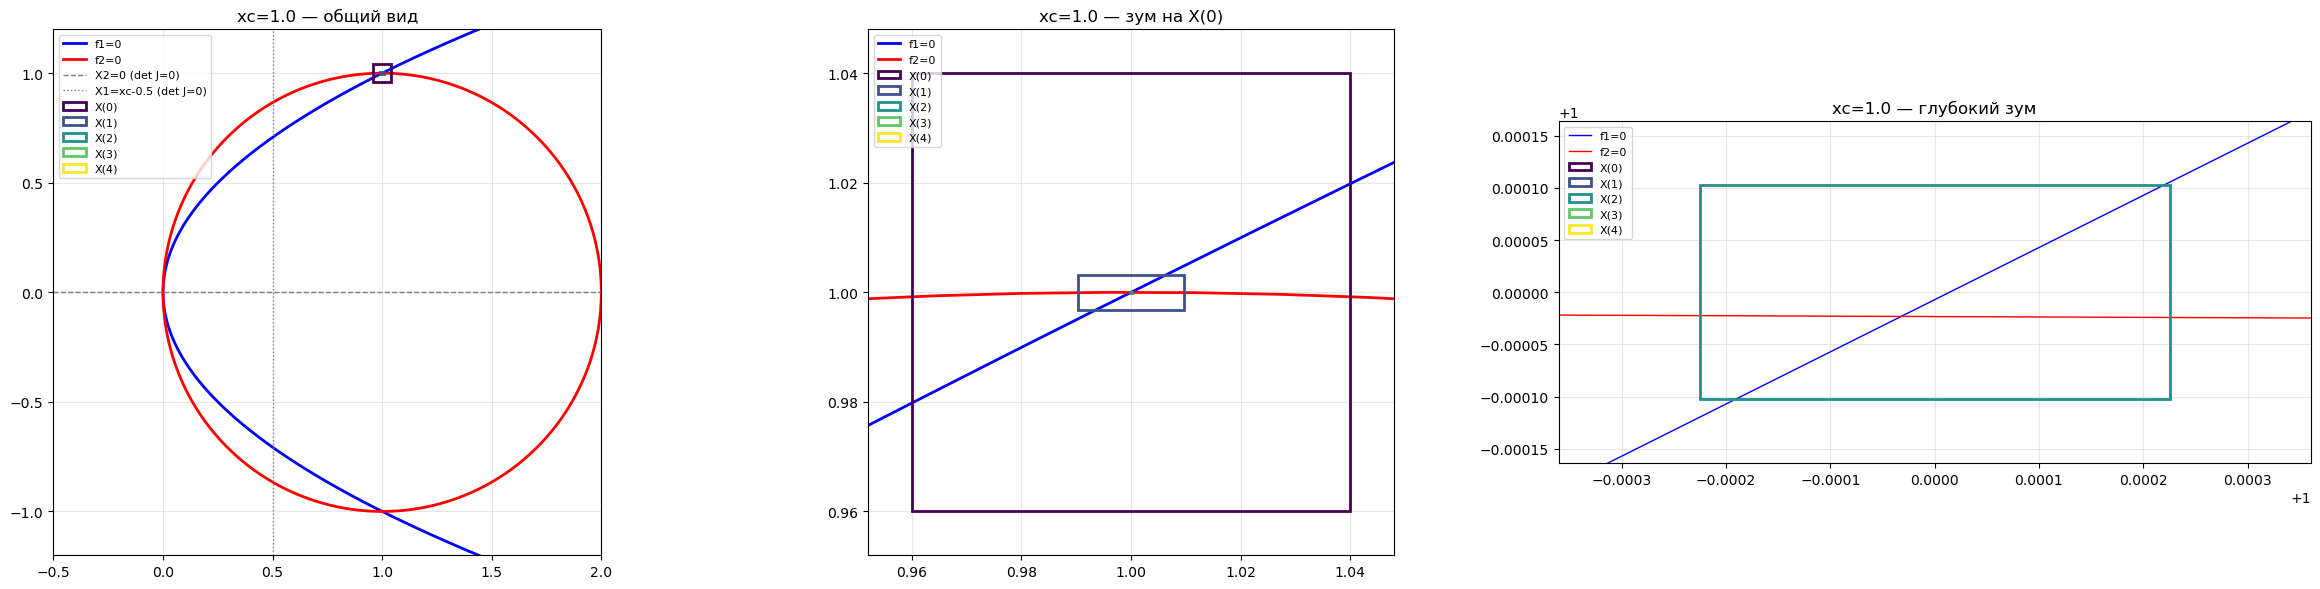

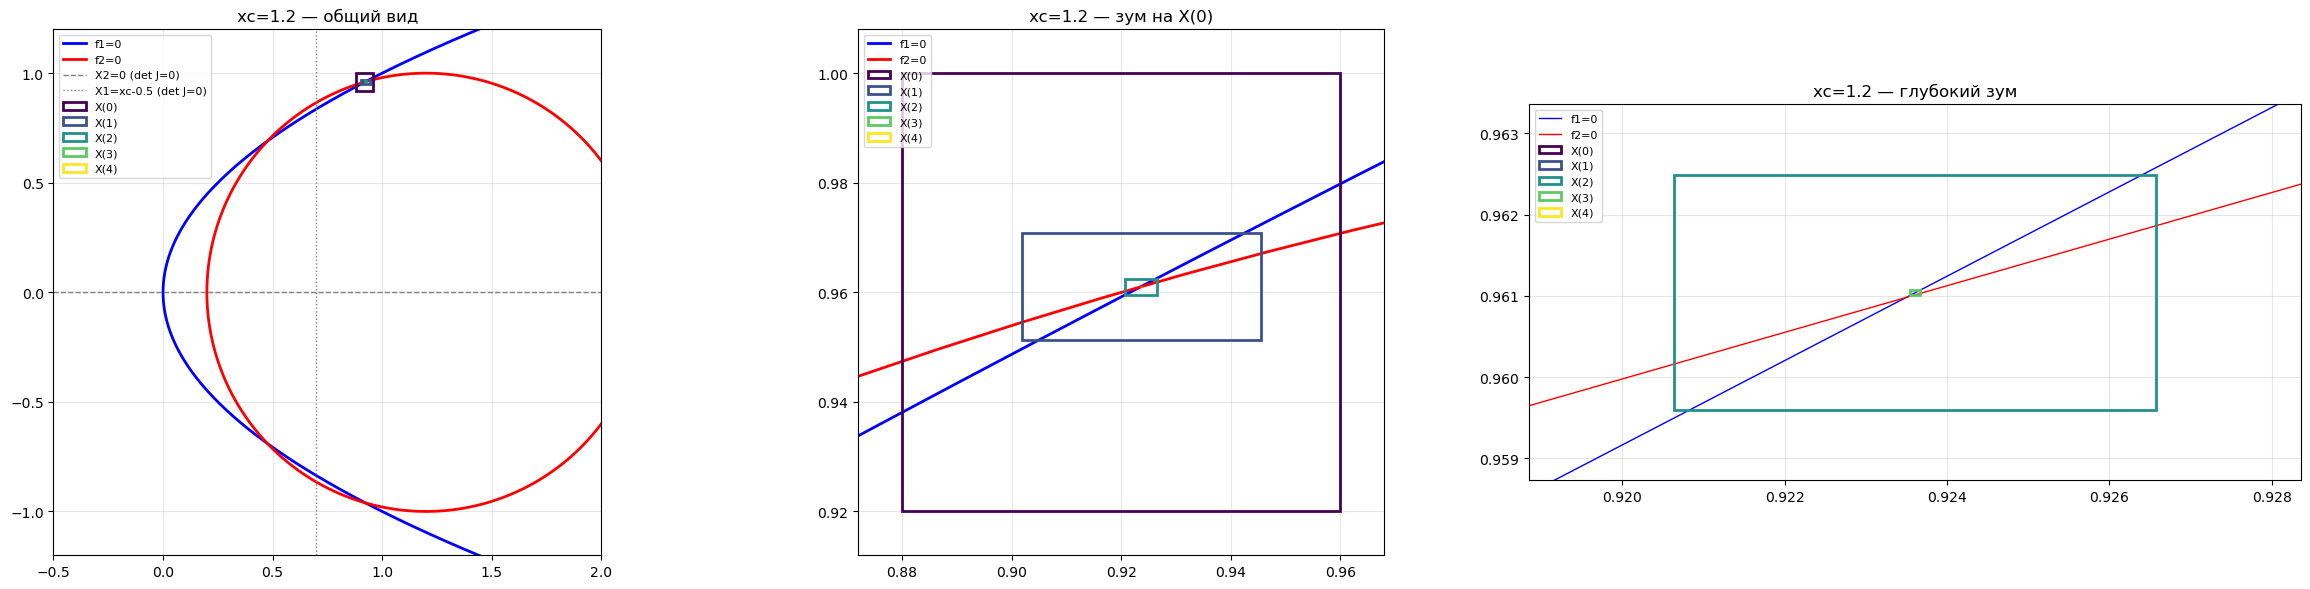

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def iadd(a, b): return (a[0] + b[0], a[1] + b[1])
def isub(a, b): return (a[0] - b[1], a[1] - b[0])
def imul(a, b):
    p = [a[0]*b[0], a[0]*b[1], a[1]*b[0], a[1]*b[1]]
    return (min(p), max(p))
def imul_num(num, a):
    p1, p2 = num*a[0], num*a[1]
    return (min(p1, p2), max(p1, p2))
def imatmul(M, v):
    res = []
    for i in range(len(M)):
        row = (0.0, 0.0)
        for j in range(len(v)):
            row = iadd(row, imul(M[i][j], v[j]))
        res.append(row)
    return res
def imatmul_mat(A, B):
    n, m = len(A), len(A[0]); p = len(B[0])
    res = [[(0.0, 0.0)]*p for _ in range(n)]
    for i in range(n):
        for j in range(p):
            s = (0.0, 0.0)
            for k in range(m):
                s = iadd(s, imul(A[i][k], B[k][j]))
            res[i][j] = s
    return res

def F_point(c, xc):
    x1, x2 = c
    return np.array([x1 - x2**2, (x1 - xc)**2 + x2**2 - 1.0])

def Jacobian_interval(X, xc):
    X1, X2 = X
    return [[(1.0, 1.0), imul_num(-2.0, X2)],
            [imul_num(2.0, isub(X1, (xc, xc))), imul_num(2.0, X2)]]

def Jacobian_point(c, xc):
    x1, x2 = c
    return np.array([[1.0, -2.0*x2],
                     [2.0*(x1 - xc), 2.0*x2]])

def midpoint(X):
    return ((X[0][0]+X[0][1])/2, (X[1][0]+X[1][1])/2)

def intersect(X, Y):
    x1 = (max(X[0][0], Y[0][0]), min(X[0][1], Y[0][1]))
    x2 = (max(X[1][0], Y[1][0]), min(X[1][1], Y[1][1]))
    if x1[0] > x1[1] or x2[0] > x2[1]:
        return None
    return (x1, x2)

def det_interval_2x2(M):
    a, b = M[0]; c, d = M[1]
    terms = [a[0]*d[0] - b[0]*c[0], a[0]*d[1] - b[0]*c[1],
             a[1]*d[0] - b[1]*c[0], a[1]*d[1] - b[1]*c[1]]
    return (min(terms), max(terms))

def krawczyk(X, xc):
    c = midpoint(X)
    JX = Jacobian_interval(X, xc)
    detJX = det_interval_2x2(JX)
    if detJX[0] <= 0 <= detJX[1]:
        return None, "det J(X) содержит 0"
    Jc = Jacobian_point(c, xc)
    try:
        Yinv_point = np.linalg.inv(Jc)
    except np.linalg.LinAlgError:
        return None, "J(c) вырождена"
    Fc = F_point(c, xc)
    step_newton = np.array(c) - Yinv_point @ Fc
    Yinv = [[(Yinv_point[i, j], Yinv_point[i, j]) for j in range(2)] for i in range(2)]
    Yinv_JX = imatmul_mat(Yinv, JX)
    I = [[(1.0, 1.0), (0.0, 0.0)], [(0.0, 0.0), (1.0, 1.0)]]
    I_minus = [[isub(I[i][j], Yinv_JX[i][j]) for j in range(2)] for i in range(2)]
    X_minus_c = [isub(X[0], (c[0], c[0])), isub(X[1], (c[1], c[1]))]
    corr = imatmul(I_minus, X_minus_c)
    N = [(step_newton[0] + corr[0][0], step_newton[0] + corr[0][1]),
         (step_newton[1] + corr[1][0], step_newton[1] + corr[1][1])]
    return N, None

xc_values = [0.0, 0.5, 1.0, 1.2]
iterations = 4

initial_boxes = {
    0.0: [((0.58, 0.66), (0.75, 0.82))],
    0.5: [((0.84, 0.89), (0.91, 0.95))],
    1.0: [((0.96, 1.04), (0.96, 1.04))],
    1.2: [((0.88, 0.96), (0.92, 1.00))],
}

all_history = {}

for xc in xc_values:
    for bi, X0 in enumerate(initial_boxes[xc]):
        label = f"xc={xc}"
        print("=" * 70)
        print(label)
        print("=" * 70)
        X_curr = X0
        history = [X_curr]
        for k in range(iterations):
            w1 = X_curr[0][1] - X_curr[0][0]
            w2 = X_curr[1][1] - X_curr[1][0]
            print(f"  k={k}: X1=[{X_curr[0][0]:.6f}, {X_curr[0][1]:.6f}] (w={w1:.6f})  "
                  f"X2=[{X_curr[1][0]:.6f}, {X_curr[1][1]:.6f}] (w={w2:.6f})")
            N, err = krawczyk(X_curr, xc)
            if N is None:
                print(f"  Остановка: {err}")
                break
            X_next = intersect(X_curr, N)
            if X_next is None:
                print("  Остановка: пересечение пустое")
                break
            w1n = X_next[0][1] - X_next[0][0]
            w2n = X_next[1][1] - X_next[1][0]
            if w1n > w1 or w2n > w2:
                print(f"  Внимание: расширение (w1: {w1:.6f}->{w1n:.6f}, w2: {w2:.6f}->{w2n:.6f})")
            X_curr = X_next
            history.append(X_curr)
        all_history[(xc, bi)] = history
        print(f"  Итог: X1=[{X_curr[0][0]:.6f}, {X_curr[0][1]:.6f}]  X2=[{X_curr[1][0]:.6f}, {X_curr[1][1]:.6f}]")

print("\n" + "=" * 70)
print("Сводная таблица сходимости")
print("=" * 70)
print(f"{'xc':>5} | {'k':>2} | {'w1':>10} | {'w2':>10}")
for (xc, bi), hist in all_history.items():
    for k, box in enumerate(hist):
        w1 = box[0][1] - box[0][0]; w2 = box[1][1] - box[1][0]
        print(f"{xc:>5} | {k:>2} | {w1:>10.6f} | {w2:>10.6f}")
    print("-" * 45)

for (xc, bi), hist in all_history.items():
    title = f"xc={xc}"
    colors = plt.cm.viridis(np.linspace(0, 1, len(hist)))

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 6))
    y_vals = np.linspace(-1.5, 1.5, 400)
    theta = np.linspace(0, 2*np.pi, 400)
    c_final = midpoint(hist[-1])

    ax1.plot(y_vals**2, y_vals, color='blue', label='f1=0', linewidth=2)
    ax1.plot(xc + np.cos(theta), np.sin(theta), color='red', label='f2=0', linewidth=2)
    ax1.axhline(0, color='gray', linestyle='--', linewidth=1, label='X2=0 (det J=0)')
    ax1.axvline(xc - 0.5, color='gray', linestyle=':', linewidth=1, label='X1=xc-0.5 (det J=0)')
    for k, box in enumerate(hist):
        rect = Rectangle((box[0][0], box[1][0]),
                         box[0][1]-box[0][0], box[1][1]-box[1][0],
                         linewidth=2, edgecolor=colors[k], facecolor='none',
                         zorder=3, label=f'X({k})')
        ax1.add_patch(rect)
    ax1.set_xlim(-0.5, 2.0)
    ax1.set_ylim(-1.2, 1.2)
    ax1.set_aspect('equal')
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc='upper left', fontsize=8)
    ax1.set_title(title + ' — общий вид')

    b0 = hist[0]
    c0 = midpoint(b0)
    pad0_x = 0.6 * (b0[0][1] - b0[0][0])
    pad0_y = 0.6 * (b0[1][1] - b0[1][0])
    ax2.plot(y_vals**2, y_vals, color='blue', label='f1=0', linewidth=2)
    ax2.plot(xc + np.cos(theta), np.sin(theta), color='red', label='f2=0', linewidth=2)
    for k, box in enumerate(hist):
        rect = Rectangle((box[0][0], box[1][0]),
                         box[0][1]-box[0][0], box[1][1]-box[1][0],
                         linewidth=2, edgecolor=colors[k], facecolor='none',
                         zorder=3, label=f'X({k})')
        ax2.add_patch(rect)
    ax2.set_xlim(c0[0]-pad0_x, c0[0]+pad0_x)
    ax2.set_ylim(c0[1]-pad0_y, c0[1]+pad0_y)
    ax2.set_aspect('equal')
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc='upper left', fontsize=8)
    ax2.set_title(title + ' — зум на X(0)')

    b2 = hist[2]
    c2 = midpoint(b2)
    pad_deep_x = 0.8 * (b2[0][1] - b2[0][0])
    pad_deep_y = 0.8 * (b2[1][1] - b2[1][0])
    ax3.plot(y_vals**2, y_vals, color='blue', label='f1=0', linewidth=1)
    ax3.plot(xc + np.cos(theta), np.sin(theta), color='red', label='f2=0', linewidth=1)
    for k, box in enumerate(hist):
        rect = Rectangle((box[0][0], box[1][0]),
                         box[0][1]-box[0][0], box[1][1]-box[1][0],
                         linewidth=2, edgecolor=colors[k], facecolor='none',
                         zorder=3, label=f'X({k})')
        ax3.add_patch(rect)
    ax3.set_xlim(c2[0]-pad_deep_x, c2[0]+pad_deep_x)
    ax3.set_ylim(c2[1]-pad_deep_y, c2[1]+pad_deep_y)
    ax3.set_aspect('equal')
    ax3.grid(True, alpha=0.3)
    ax3.legend(loc='upper left', fontsize=8)
    ax3.set_title(title + ' — глубокий зум')

    plt.tight_layout()
    plt.show()

In [4]:
print("=" * 75)
print("Анализ влияния начального приближения (xc = 1.2)")
print("=" * 75)

test_boxes = [
    ("a) В области без решения",       ((1.20, 1.40), (1.20, 1.40))),
    ("b) Слишком широкий",             ((0.50, 1.10), (0.50, 1.10))),
    ("c) Узкий, вокруг решения",       ((0.88, 0.96), (0.92, 1.00))),
    ("d) Центр вне линии, брус накрывает X1=0.7", ((0.65, 0.95), (0.80, 1.00))),
]

for name, X0 in test_boxes:
    print(f"\n--- {name} ---")
    print(f"X^(0) = X1=[{X0[0][0]:.3f}, {X0[0][1]:.3f}], "
          f"X2=[{X0[1][0]:.3f}, {X0[1][1]:.3f}]")
    c = ((X0[0][0] + X0[0][1]) / 2, (X0[1][0] + X0[1][1]) / 2)
    print(f"  центр c = ({c[0]:.3f}, {c[1]:.3f})")
    X_curr = X0
    for k in range(4):
        N, err = krawczyk(X_curr, 1.2)
        if N is None:
            print(f"  k={k}: остановка — {err}")
            break
        X_next = intersect(X_curr, N)
        if X_next is None:
            print(f"  k={k}: остановка — пересечение пустое")
            break
        w_prev = (X_curr[0][1]-X_curr[0][0]) + (X_curr[1][1]-X_curr[1][0])
        w_next = (X_next[0][1]-X_next[0][0]) + (X_next[1][1]-X_next[1][0])
        flag = "  (расширение!)" if w_next > w_prev else ""
        print(f"  k={k}->k={k+1}: X1=[{X_next[0][0]:.6f}, {X_next[0][1]:.6f}], "
              f"X2=[{X_next[1][0]:.6f}, {X_next[1][1]:.6f}]{flag}")
        X_curr = X_next
    else:
        print(f"  Итог: X1=[{X_curr[0][0]:.6f}, {X_curr[0][1]:.6f}], "
              f"X2=[{X_curr[1][0]:.6f}, {X_curr[1][1]:.6f}]")

Анализ влияния начального приближения (xc = 1.2)

--- a) В области без решения ---
X^(0) = X1=[1.200, 1.400], X2=[1.200, 1.400]
  центр c = (1.300, 1.300)
  k=0: остановка — пересечение пустое

--- b) Слишком широкий ---
X^(0) = X1=[0.500, 1.100], X2=[0.500, 1.100]
  центр c = (0.800, 0.800)
  k=0: остановка — det J(X) содержит 0

--- c) Узкий, вокруг решения ---
X^(0) = X1=[0.880, 0.960], X2=[0.920, 1.000]
  центр c = (0.920, 0.960)
  k=0->k=1: X1=[0.901818, 0.945455], X2=[0.951364, 0.970758]
  k=1->k=2: X1=[0.920637, 0.926576], X2=[0.959598, 0.962492]
  k=2->k=3: X1=[0.923549, 0.923665], X2=[0.961017, 0.961073]
  k=3->k=4: X1=[0.923607, 0.923607], X2=[0.961045, 0.961045]
  Итог: X1=[0.923607, 0.923607], X2=[0.961045, 0.961045]

--- d) Центр вне линии, брус накрывает X1=0.7 ---
X^(0) = X1=[0.650, 0.950], X2=[0.800, 1.000]
  центр c = (0.800, 0.900)
  k=0: остановка — det J(X) содержит 0
